# MaxViT — Multi-Axis Vision Transformer

**Paper:** Z. Tu, H. Talebi, H. Zhang, F. Yang, P. Milanfar, A. Bovik, and Y. Li,
"MaxViT: Multi-Axis Vision Transformer,"
in *Proc. European Conference on Computer Vision (ECCV)*, 2022, pp. 459–479.
arXiv: [2204.01697](https://arxiv.org/abs/2204.01697)

> **One-line summary:** A linear-complexity ViT that combines local block attention
> (P×P windows) and global dilated-grid attention in every block, giving full
> receptive field at O(N) cost instead of O(N²).


> 📄 **Paper:** Tu et al. (2022). MaxViT: Multi-Axis Vision Transformer. ECCV 2022.
> 🔗 **Link:** <https://arxiv.org/abs/2204.01697>
> 🧩 **Implementation:** `hale_core/nn/vision/hybrid/maxvit.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["stem: 2 × conv 3×3 /2 → 64"]:::stage
  STEM --> S["4 stages ×[2,2,5,2], widths 64·128·256·512, /4 … /32"]:::stage --> GAP["avg pool · norm"]:::block --> OUT
  subgraph BLK["MaxViT block"]
    direction LR
    X["x"] --> MB["MBConv + SE"]:::block --> BA["block attention<br/>local P×P windows"]:::block --> GA["grid attention<br/>sparse global G×G dilated grid"]:::block --> Y["out"]
  end
  S -.-> BLK
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Pipeline (ASCII)

```
Input Image [B, 3, 224, 224]
        │
        ▼
┌─────────────────────────────────────────┐
│  Stem: Conv(3→64, 3×3 s=2)             │  → [B, 64, 112, 112]
│         Conv(64→64, 3×3 s=1)           │
└─────────────────────┬───────────────────┘
                      │
      ┌───────────────▼───────────────┐
      │  Stage 0  [B, 64, 56, 56]    │
      │  stride-2 MBConv + N blocks  │
      │                              │
      │  Each MaxViT Block:          │
      │    MBConv (conv pre-stage)   │
      │    → Block Attn (local P×P) │
      │    → Grid Attn (global dil) │
      └───────────────┬──────────────┘
                      │
      ┌───────────────▼───────────────┐
      │  Stage 1  [B, 128, 28, 28]   │
      └───────────────┬──────────────┘
                      │
      ┌───────────────▼───────────────┐
      │  Stage 2  [B, 256, 14, 14]   │
      └───────────────┬──────────────┘
                      │
      ┌───────────────▼───────────────┐
      │  Stage 3  [B, 512,  7,  7]   │
      └───────────────┬──────────────┘
                      │
               Global Avg Pool
                      │
              pooled_output [B, 512]

──────────────────────────────────────────────────────────────────
 MaxViT Block (per block in every stage)
──────────────────────────────────────────────────────────────────

  x [B, C, H, W]  (channels-first)
       │
  MBConv  (local conv features, stride=1)
       │
  to channels-last + pad H,W → multiple of block_size P
       │
  ╔════════════════════════════════════╗
  ║  Block Attention (local)           ║
  ║  block_partition → [B*nH*nW, P², C]║
  ║  LN → MHSA + rel_bias → FFN        ║
  ║  block_reverse → [B, H, W, C]      ║
  ╚════════════════════════════════════╝
       │
  ╔════════════════════════════════════╗
  ║  Grid Attention (global dilated)   ║
  ║  grid_partition → [B*P², G², C]    ║
  ║  LN → MHSA + rel_bias → FFN        ║
  ║  grid_reverse → [B, H, W, C]       ║
  ╚════════════════════════════════════╝
       │
  unpad → back to channels-first
  x [B, C, H, W]
```


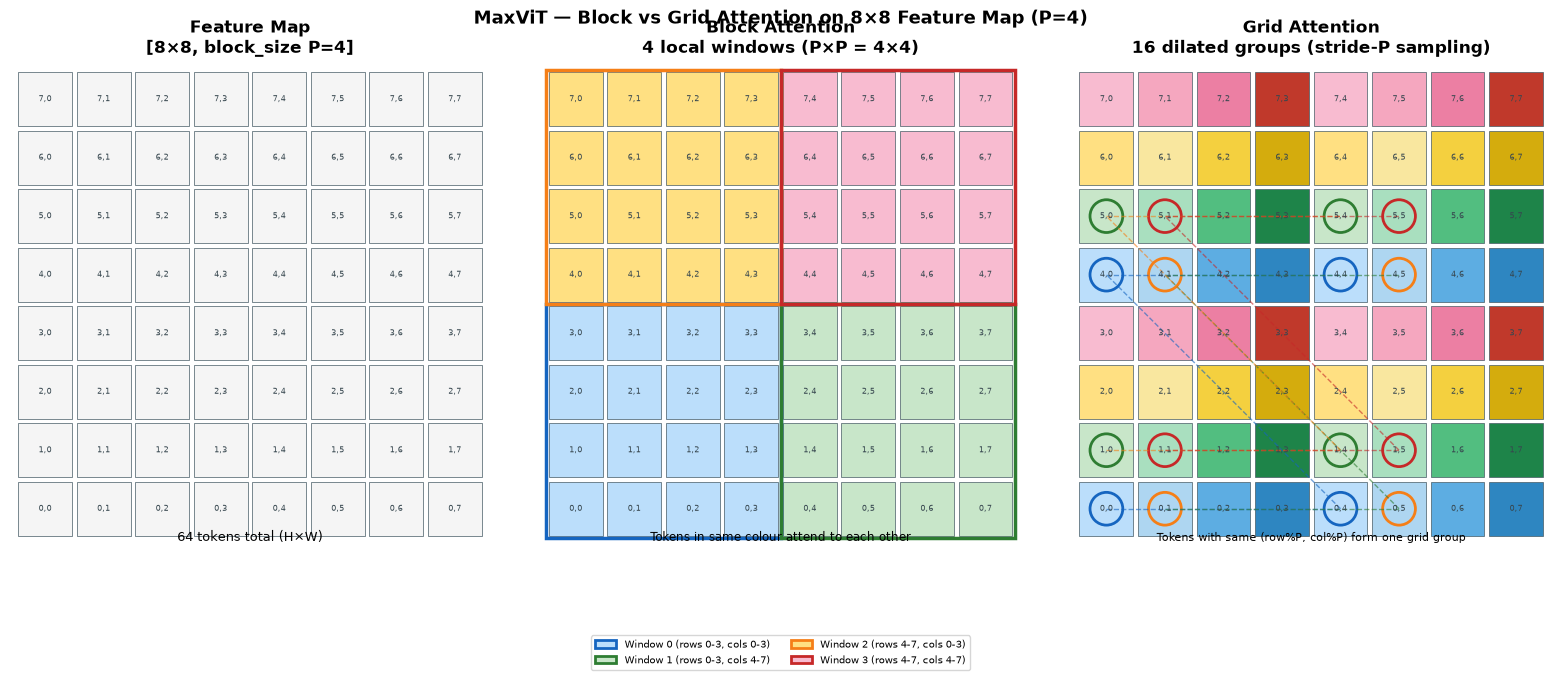

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import to_rgba
import numpy as np

# ════════════════════════════════════════════════════════════════════════════
# Figure 1: Block vs Grid partition visual on an 8×8 feature map, P=4
# ════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

def draw_grid(ax, title, cell_colors, border_color='#455a64', window_borders=None):
    """Draw an 8×8 grid with given cell colours and optional thick window borders."""
    ax.set_xlim(-0.1, 8.1)
    ax.set_ylim(-0.1, 8.1)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)

    for row in range(8):
        for col in range(8):
            color = cell_colors[row][col]
            rect = mpatches.FancyBboxPatch(
                (col + 0.04, row + 0.04), 0.92, 0.92,
                boxstyle='square,pad=0.0', facecolor=color,
                edgecolor=border_color, linewidth=0.5)
            ax.add_patch(rect)
            ax.text(col + 0.5, row + 0.5, f'{row},{col}',
                    ha='center', va='center', fontsize=5.5, color='#37474f')

    if window_borders:
        for (r0, c0, r1, c1, color, lw) in window_borders:
            rect = mpatches.Rectangle(
                (c0, r0), c1 - c0, r1 - r0,
                fill=False, edgecolor=color, linewidth=lw)
            ax.add_patch(rect)

# Colour palette for windows
W_COLORS = [
    '#bbdefb',  # W0 — top-left  block
    '#c8e6c9',  # W1 — top-right block
    '#ffe082',  # W2 — bottom-left block
    '#f8bbd0',  # W3 — bottom-right block
]
G_COLORS = [
    '#bbdefb',  # Grid 0 (top-left in each block)
    '#c8e6c9',  # Grid 1 (top-right in each block)
    '#ffe082',  # Grid 2 (bottom-left in each block)
    '#f8bbd0',  # Grid 3 (bottom-right in each block)
]

# ── Panel A: Neutral baseline (no attention)
neutral = [['#f5f5f5'] * 8 for _ in range(8)]
draw_grid(axes[0], 'Feature Map\n[8×8, block_size P=4]', neutral)
axes[0].text(4, -0.05, '64 tokens total (H×W)', ha='center', fontsize=9)

# ── Panel B: Block (local window) attention
# 4 contiguous windows of 4×4 tokens: TL, TR, BL, BR
block_colors = [[''] * 8 for _ in range(8)]
for row in range(8):
    for col in range(8):
        qr, qc = row // 4, col // 4   # which quadrant (0–3)
        win_id = qr * 2 + qc
        block_colors[row][col] = W_COLORS[win_id]

block_borders = [
    (0, 0, 4, 4, '#1565c0', 2.5),   # window 0
    (0, 4, 4, 8, '#2e7d32', 2.5),   # window 1
    (4, 0, 8, 4, '#f57f17', 2.5),   # window 2
    (4, 4, 8, 8, '#c62828', 2.5),   # window 3
]
draw_grid(axes[1], 'Block Attention\n4 local windows (P×P = 4×4)',
          block_colors, window_borders=block_borders)
axes[1].text(4, -0.05, 'Tokens in same colour attend to each other', ha='center', fontsize=8.5)

legend_b = [
    mpatches.Patch(fc='#bbdefb', ec='#1565c0', lw=2, label='Window 0 (rows 0-3, cols 0-3)'),
    mpatches.Patch(fc='#c8e6c9', ec='#2e7d32', lw=2, label='Window 1 (rows 0-3, cols 4-7)'),
    mpatches.Patch(fc='#ffe082', ec='#f57f17', lw=2, label='Window 2 (rows 4-7, cols 0-3)'),
    mpatches.Patch(fc='#f8bbd0', ec='#c62828', lw=2, label='Window 3 (rows 4-7, cols 4-7)'),
]
axes[1].legend(handles=legend_b, loc='upper center', bbox_to_anchor=(0.5, -0.18),
               fontsize=7.5, ncol=2, frameon=True)

# ── Panel C: Grid (dilated global) attention
# grid_partition with P=4: each of the 4×4=16 positions within a block forms
# a group of (8/4)×(8/4)=4 tokens spread across the whole map.
# Colour by (row%P, col%P) = local position within block.
grid_colors = [[''] * 8 for _ in range(8)]
grid_group_colors = [
    ['#bbdefb', '#aed6f1', '#5dade2', '#2e86c1'],  # row%4==0
    ['#c8e6c9', '#a9dfbf', '#52be80', '#1e8449'],  # row%4==1
    ['#ffe082', '#f9e79f', '#f4d03f', '#d4ac0d'],  # row%4==2
    ['#f8bbd0', '#f5a7bf', '#ec7fa3', '#c0392b'],  # row%4==3
]
for row in range(8):
    for col in range(8):
        grid_colors[row][col] = grid_group_colors[row % 4][col % 4]

# Overlay: mark same-group cells with a circle (all tokens with same (r%4, c%4))
draw_grid(axes[2], 'Grid Attention\n16 dilated groups (stride-P sampling)',
          grid_colors)

# Draw dotted lines connecting same-group tokens for 4 example groups
example_groups = [(0, 0), (0, 1), (1, 0), (1, 1)]
group_display_colors = ['#1565c0', '#2e7d32', '#f57f17', '#c62828']
for (gr, gc), gcolor in zip(example_groups, group_display_colors):
    pts = [(r + 0.5, c + 0.5) for r in range(8) for c in range(8) if r % 4 == gr and c % 4 == gc]
    for p in pts:
        circ = plt.Circle(p, 0.28, fill=False, ec=gcolor, lw=2.0)
        axes[2].add_patch(circ)
    for i in range(len(pts) - 1):
        axes[2].plot([pts[i][1], pts[i+1][1]], [pts[i][0], pts[i+1][0]],
                     color=gcolor, lw=1.0, linestyle='--', alpha=0.6)

axes[2].text(4, -0.05, 'Tokens with same (row%P, col%P) form one grid group', ha='center', fontsize=8)

plt.suptitle('MaxViT — Block vs Grid Attention on 8×8 Feature Map (P=4)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()

plt.show()

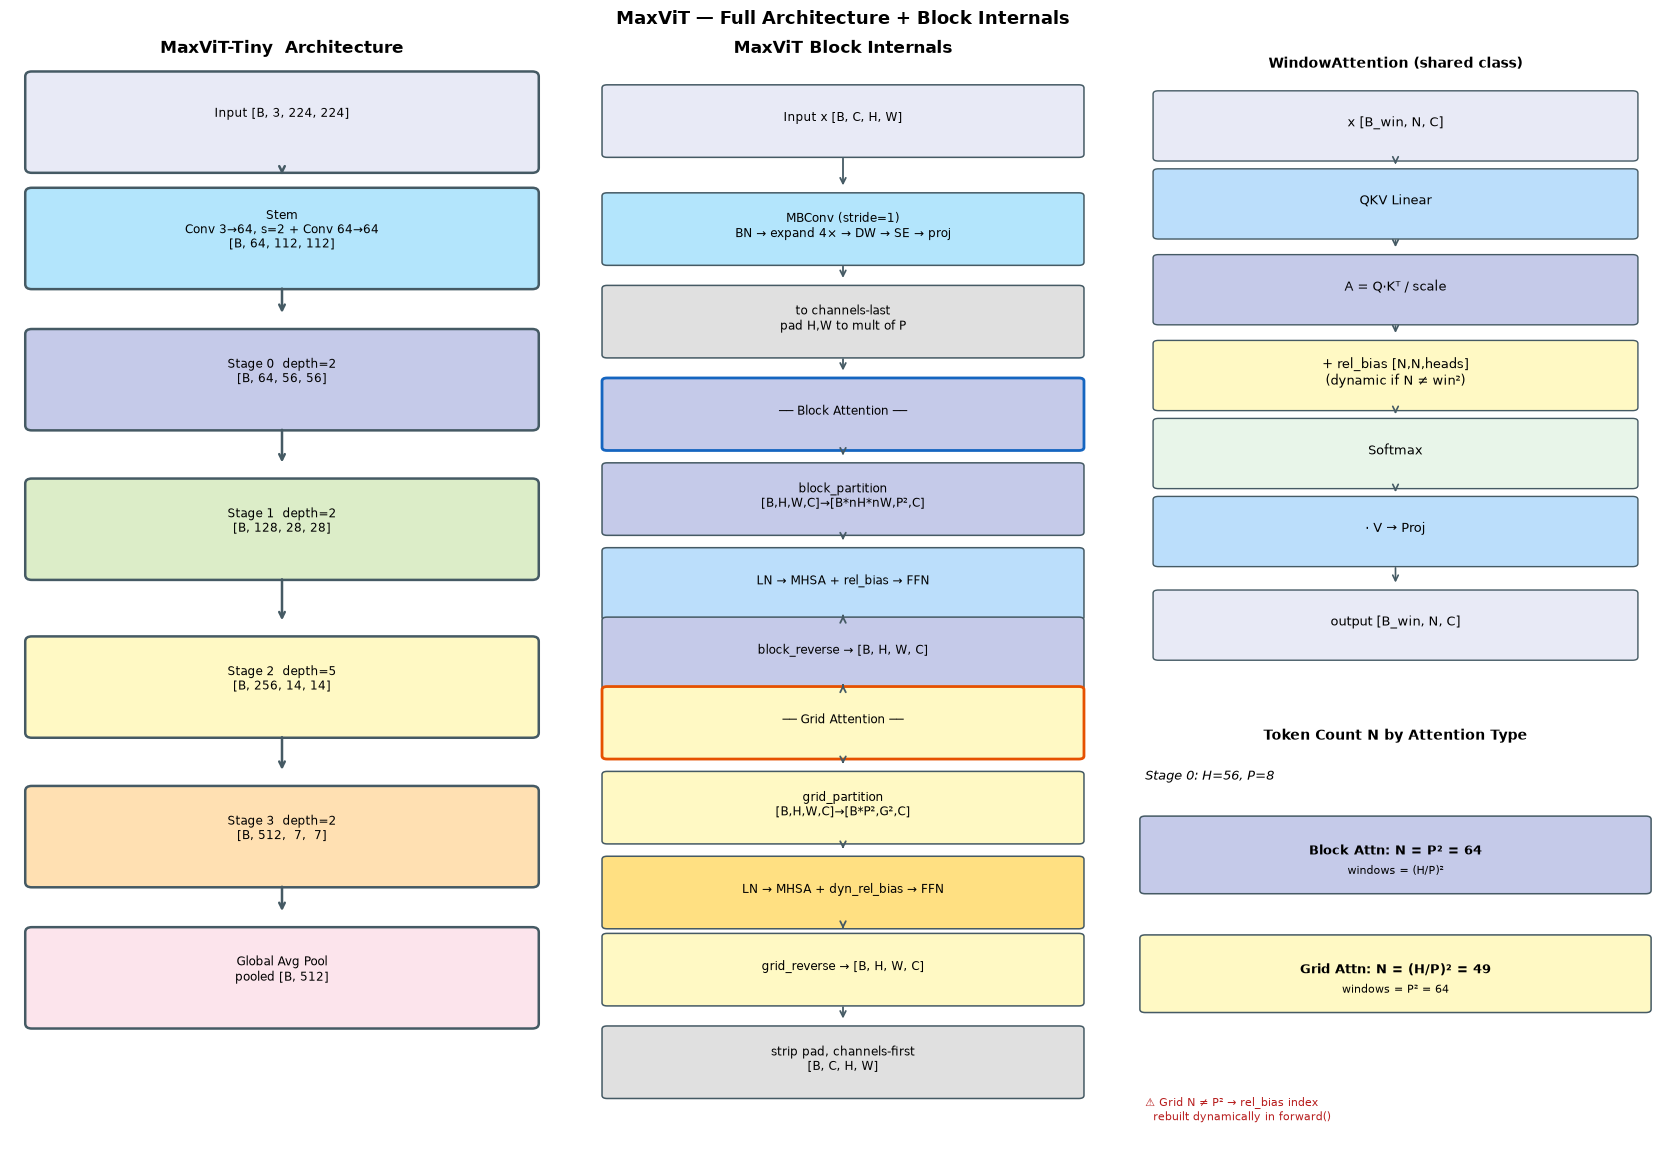

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# ════════════════════════════════════════════════════════════════════════════
# Figure 2: MaxViT block internals and full model architecture
# ════════════════════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(17, 12))

# ── Left: full model stages ─────────────────────────────────────────────────
ax1 = fig.add_axes([0.01, 0.05, 0.32, 0.90])
ax1.set_xlim(0, 5)
ax1.set_ylim(0, 13)
ax1.axis('off')
ax1.set_title('MaxViT-Tiny  Architecture', fontsize=12, fontweight='bold', pad=8)

model_stages = [
    ('Input [B, 3, 224, 224]',         12.4, '#e8eaf6'),
    ('Stem\nConv 3→64, s=2 + Conv 64→64\n[B, 64, 112, 112]', 11.0, '#b3e5fc'),
    ('Stage 0  depth=2\n[B, 64, 56, 56]', 9.3, '#c5cae9'),
    ('Stage 1  depth=2\n[B, 128, 28, 28]', 7.5, '#dcedc8'),
    ('Stage 2  depth=5\n[B, 256, 14, 14]', 5.6, '#fff9c4'),
    ('Stage 3  depth=2\n[B, 512,  7,  7]', 3.8, '#ffe0b2'),
    ('Global Avg Pool\npooled [B, 512]',   2.1, '#fce4ec'),
]
for label, y, color in model_stages:
    box = FancyBboxPatch((0.2, y - 0.65), 4.6, 1.1,
                         boxstyle='round,pad=0.06', facecolor=color,
                         edgecolor='#455a64', linewidth=1.8)
    ax1.add_patch(box)
    ax1.text(2.5, y, label, ha='center', va='center', fontsize=8.5)

for i in range(len(model_stages) - 1):
    y1 = model_stages[i][1] - 0.67
    y2 = model_stages[i+1][1] + 0.67
    ax1.annotate('', xy=(2.5, y2), xytext=(2.5, y1),
                 arrowprops=dict(arrowstyle='->', color='#455a64', lw=1.8))

# ── Middle: MaxViT block internals ──────────────────────────────────────────
ax2 = fig.add_axes([0.35, 0.05, 0.30, 0.90])
ax2.set_xlim(0, 4)
ax2.set_ylim(0, 14)
ax2.axis('off')
ax2.set_title('MaxViT Block Internals', fontsize=12, fontweight='bold', pad=8)

block_items = [
    ('Input x [B, C, H, W]', 13.3, '#e8eaf6'),
    ('MBConv (stride=1)\nBN → expand 4× → DW → SE → proj', 11.9, '#b3e5fc'),
    ('to channels-last\npad H,W to mult of P', 10.7, '#e0e0e0'),
    ('── Block Attention ──', 9.5, '#c5cae9'),
    ('block_partition\n[B,H,W,C]→[B*nH*nW,P²,C]', 8.4, '#c5cae9'),
    ('LN → MHSA + rel_bias → FFN', 7.3, '#bbdefb'),
    ('block_reverse → [B, H, W, C]', 6.4, '#c5cae9'),
    ('── Grid Attention ──', 5.5, '#fff9c4'),
    ('grid_partition\n[B,H,W,C]→[B*P²,G²,C]', 4.4, '#fff9c4'),
    ('LN → MHSA + dyn_rel_bias → FFN', 3.3, '#ffe082'),
    ('grid_reverse → [B, H, W, C]', 2.3, '#fff9c4'),
    ('strip pad, channels-first\n[B, C, H, W]', 1.1, '#e0e0e0'),
]
for label, y, color in block_items:
    lw = 2.0 if '──' in label else 1.1
    ec = '#1565c0' if 'Block' in label else ('#e65100' if 'Grid' in label else '#455a64')
    box = FancyBboxPatch((0.15, y - 0.47), 3.70, 0.86,
                         boxstyle='round,pad=0.04', facecolor=color,
                         edgecolor=ec, linewidth=lw)
    ax2.add_patch(box)
    ax2.text(2.0, y, label, ha='center', va='center', fontsize=8.5)

for i in range(len(block_items) - 1):
    y1 = block_items[i][1] - 0.49
    y2 = block_items[i+1][1] + 0.49
    ax2.annotate('', xy=(2.0, y2), xytext=(2.0, y1),
                 arrowprops=dict(arrowstyle='->', color='#455a64', lw=1.3))

# ── Right: WindowAttention (block vs grid) ──────────────────────────────────
ax3 = fig.add_axes([0.67, 0.42, 0.31, 0.52])
ax3.set_xlim(0, 4)
ax3.set_ylim(0, 8)
ax3.axis('off')
ax3.set_title('WindowAttention (shared class)', fontsize=10, fontweight='bold', pad=6)

attn_items = [
    ('x [B_win, N, C]', 7.4, '#e8eaf6'),
    ('QKV Linear', 6.4, '#bbdefb'),
    ('A = Q·Kᵀ / scale', 5.3, '#c5cae9'),
    ('+ rel_bias [N,N,heads]\n(dynamic if N ≠ win²)', 4.2, '#fff9c4'),
    ('Softmax', 3.2, '#e8f5e9'),
    ('· V → Proj', 2.2, '#bbdefb'),
    ('output [B_win, N, C]', 1.0, '#e8eaf6'),
]
for label, y, color in attn_items:
    box = FancyBboxPatch((0.2, y - 0.45), 3.6, 0.82,
                         boxstyle='round,pad=0.04', facecolor=color,
                         edgecolor='#455a64', linewidth=1.0)
    ax3.add_patch(box)
    ax3.text(2.0, y, label, ha='center', va='center', fontsize=9)

for i in range(len(attn_items) - 1):
    y1 = attn_items[i][1] - 0.47
    y2 = attn_items[i+1][1] + 0.47
    ax3.annotate('', xy=(2.0, y2), xytext=(2.0, y1),
                 arrowprops=dict(arrowstyle='->', color='#455a64', lw=1.2))

# ── Right bottom: N for block vs grid ───────────────────────────────────────
ax4 = fig.add_axes([0.67, 0.05, 0.31, 0.33])
ax4.set_xlim(0, 4)
ax4.set_ylim(0, 5)
ax4.axis('off')
ax4.set_title('Token Count N by Attention Type', fontsize=10, fontweight='bold', pad=6)

rows = [
    ('Block Attn', 'N = P² = 64',   'windows = (H/P)²', '#c5cae9'),
    ('Grid Attn',  'N = (H/P)² = 49', 'windows = P² = 64', '#fff9c4'),
]
ax4.text(0.1, 4.6, 'Stage 0: H=56, P=8', fontsize=9, style='italic')
for i, (typ, n_val, win_val, color) in enumerate(rows):
    y = 3.6 - i * 1.5
    box = FancyBboxPatch((0.1, y - 0.4), 3.8, 0.9,
                         boxstyle='round,pad=0.04', facecolor=color,
                         edgecolor='#455a64', linewidth=1.1)
    ax4.add_patch(box)
    ax4.text(2.0, y + 0.1, f'{typ}: {n_val}', ha='center', va='center', fontsize=9, fontweight='bold')
    ax4.text(2.0, y - 0.15, win_val, ha='center', va='center', fontsize=8)

ax4.text(0.1, 0.3,
    '⚠ Grid N ≠ P² → rel_bias index\n  rebuilt dynamically in forward()',
    fontsize=8, color='#b71c1c')

plt.suptitle('MaxViT — Full Architecture + Block Internals', fontsize=13, fontweight='bold', y=0.995)

plt.show()

## 3. Key ideas

## Key Innovations

### 1. O(N) Multi-Axis Attention

Global attention has cost $O(N^2)$. MaxViT solves this with two complementary patterns:

**Block attention** (local): partition into $\left(\frac{H}{P}\right)^2$ windows of $P^2$ tokens:
$$\text{cost} = \frac{H \cdot W}{P^2} \cdot P^4 = H \cdot W \cdot P^2 = O(N \cdot P^2)$$

**Grid attention** (global): partition into $P^2$ groups of $\left(\frac{H}{P}\right)^2$ tokens:
$$\text{cost} = P^2 \cdot \left(\frac{HW}{P^2}\right)^2 \cdot \frac{1}{P^2} = \frac{H^2 W^2}{P^4}$$

Wait — but since $P$ is constant (e.g. 8) and $H, W$ scale: grid cost is $O(N^2 / P^2)$
which is *cheaper* than full attention but still $O(N)$ when $P$ is fixed.
Combined: **both heads run at linear complexity w.r.t. image size $N = H \cdot W$.**

### 2. Block Partition (O(1) reshape)

```
block_partition(x, P):  [B, H, W, C] → [B*nH*nW, P, P, C]
  nH = H//P,  nW = W//P
  x.view(B, nH, P, nW, P, C)
  .permute(0, 1, 3, 2, 4, 5)   →  [B, nH, nW, P, P, C]
  .reshape(B*nH*nW, P, P, C)
```

No data is copied — all operations are O(1) reshape + permute.

### 3. Grid Partition (O(1) reshape)

```
grid_partition(x, P):   [B, H, W, C] → [B*P*P, H//P, W//P, C]
  gh = H//P,  gw = W//P
  x.view(B, gh, P, gw, P, C)
  .permute(0, 2, 4, 1, 3, 5)   →  [B, P, P, gh, gw, C]
  .reshape(B*P*P, gh, gw, C)
```

Same reshapes — just different permute order. Grid attention picks every P-th pixel
globally, giving each window a full-image receptive field at low cost.

### 4. Dynamic Relative Bias

Block attention: window has $N = P^2$ tokens → relative bias table sized $(2P-1)^2$.

Grid attention: window has $N = (H//P)^2$ tokens → **different** size.
In our implementation, `WindowAttention.forward` detects when runtime $N \neq P^2$
and recomputes the relative position index dynamically, clamping to the pre-allocated table:

```python
win = int(N ** 0.5)
if win != self.window_size:
    idx = self._build_rel_index(win, x.device)   # dynamic computation
idx_clamped = idx.clamp(0, table_size - 1)        # stay in-bounds
bias = self.rel_bias_table[idx_clamped]           # [N², heads]
```

### 5. Padding Strategy

Both block and grid partition require $H$ and $W$ to be multiples of $P$.
For inputs where this fails (e.g. $H=7$, $P=8$), MaxViT pads before attention and
strips the pad after:

```python
pad_h = (P - H % P) % P    # 0 if already divisible
x = F.pad(x, (0,0, 0,pad_w, 0,pad_h))  # channels-last padding
# ... attention on Hp×Wp ...
x = x[:, :H, :W, :]        # strip pad
```

### 6. Model Variants

| Model | Base dim | Depths | Params |
|-------|---------|--------|--------|
| maxvit_tiny | 64 | [2,2,5,2] | ~31 M |
| maxvit_small | 96 | [2,2,5,2] | ~69 M |
| maxvit_base | 96 | [2,6,14,2] | ~120 M |
| maxvit_large | 128 | [2,6,14,2] | ~212 M |
| maxvit_xlarge | 192 | [2,6,14,2] | ~475 M |


## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/hybrid/maxvit.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>hybrid/maxvit.py</code></summary>

```text
MaxViT — Multi-Axis Vision Transformer (Tu et al., 2022)
=========================================================

Reference: "MaxViT: Multi-Axis Vision Transformer"
           https://arxiv.org/abs/2204.01697

Architecture overview
---------------------
MaxViT solves the O(N²) attention problem for high-resolution images by
interleaving two complementary attention patterns in every block:

1. **Local Block Attention** (window / "block" attention):
   Partitions the spatial map into non-overlapping windows of size P×P
   (e.g. 8×8). Self-attention runs inside each window independently.
   → Captures fine-grained local patterns.

2. **Dilated Grid Attention** (global / "grid" attention):
   Instead of attending over a local patch, picks tokens spaced regularly
   across the entire image with stride = window_size. Each of the resulting
   G×G grids (where G = window_size for a square image) sees a sparse but
   GLOBAL set of positions.
   → Captures long-range dependencies cheaply.

Every MaxViT block applies BOTH: local first, then global.
Combined complexity: O(N · P²) instead of O(N²) for full attention.
This gives full global receptive field at linear cost.

Partition helpers (O(1) reshape — no data copy)
-----------------------------------------------
  block_partition(x, block_size):
      [B, H, W, C] → [B * nH * nW, P, P, C]   where P = block_size
      Splits image into a grid of P×P blocks.

  grid_partition(x, grid_size):
      [B, H, W, C] → [B * P * P, G, G, C]      where G = H // grid_size
      Picks every grid_size-th pixel as one "grid window".

Block layout per MaxViT block
------------------------------
  MBConv (depth-wise conv + SE + BN pre-norm)
    ↓
  Block Attention (local window, pre-LN, residual)
    ↓
  Grid Attention (dilated global, pre-LN, residual)

Both attention sub-layers also have a post-attention FFN sublayer.

Stem: Conv(3→dim, 3×3, stride=2) → Conv(dim→dim, 3×3, stride=1)
4 stages: each stage doubles channels and halves spatial resolution.

BackboneOutput
--------------
  pooled_output : [B, dim*8]   — global avg pool of stage 3 output
  feature_maps  : 4 maps, [B, dim*(2^i), H/(2^(i+2)), W/(2^(i+2))]
  patch_tokens  : None
```
</details>

In [3]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [4]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [5]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `hybrid/maxvit.py`, definition by definition

In [6]:
def _trunc_normal_(t: torch.Tensor, std: float = 0.02) -> torch.Tensor:
    with torch.no_grad():
        return t.normal_(0, std).clamp_(-2 * std, 2 * std)

**`DropPath`** - Stochastic depth — drop entire residual branch per sample.

In [7]:
class DropPath(nn.Module):
    """Stochastic depth — drop entire residual branch per sample."""

    def __init__(self, drop_prob: float = 0.0) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0:
            return x
        keep = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        noise = torch.rand(shape, device=x.device, dtype=x.dtype).floor_() + keep
        return x.div(keep) * noise

In [8]:
def block_partition(x: torch.Tensor, block_size: int) -> torch.Tensor:
    """Partition spatial map into non-overlapping blocks.

    Each block of P×P pixels is one "window" for local attention.

    Args:
        x:          [B, H, W, C]  (channels-last)
        block_size: P — local window height == width

    Returns:
        blocks: [B * nH * nW, P, P, C]  where nH=H//P, nW=W//P
    """
    B, H, W, C = x.shape
    nH, nW = H // block_size, W // block_size
    x = x.view(B, nH, block_size, nW, block_size, C)
    x = x.permute(0, 1, 3, 2, 4, 5).contiguous()
    return x.view(B * nH * nW, block_size, block_size, C)

In [9]:
def block_reverse(
    blocks: torch.Tensor, block_size: int, H: int, W: int
) -> torch.Tensor:
    """Reconstruct [B, H, W, C] from [B*nH*nW, P, P, C]."""
    nH, nW = H // block_size, W // block_size
    B = blocks.shape[0] // (nH * nW)
    x = blocks.view(B, nH, nW, block_size, block_size, -1)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)

In [10]:
def grid_partition(x: torch.Tensor, grid_size: int) -> torch.Tensor:
    """Partition into dilated grids for global attention.

    Instead of contiguous patches, takes every grid_size-th pixel.
    This gives each grid window a full-image receptive field at O(G²) cost.

    Example: 32×32 image, grid_size=8 → 8×8=64 windows, each 4×4 tokens.

    Args:
        x:         [B, H, W, C]
        grid_size: G — stride between picked pixels

    Returns:
        grids: [B * G * G, H//G, W//G, C]
    """
    B, H, W, C = x.shape
    gh, gw = H // grid_size, W // grid_size
    x = x.view(B, gh, grid_size, gw, grid_size, C)
    x = x.permute(0, 2, 4, 1, 3, 5).contiguous()
    return x.view(B * grid_size * grid_size, gh, gw, C)

In [11]:
def grid_reverse(
    grids: torch.Tensor, grid_size: int, H: int, W: int
) -> torch.Tensor:
    """Reconstruct [B, H, W, C] from [B*G*G, H//G, W//G, C]."""
    gh, gw = H // grid_size, W // grid_size
    B = grids.shape[0] // (grid_size * grid_size)
    x = grids.view(B, grid_size, grid_size, gh, gw, -1)
    return x.permute(0, 3, 1, 4, 2, 5).contiguous().view(B, H, W, -1)

**`WindowAttention`** - Vanilla multi-head self-attention with 2D relative position bias.

In [12]:
class WindowAttention(nn.Module):
    """Vanilla multi-head self-attention with 2D relative position bias.

    Used for both block and grid attention in MaxViT.
    The relative bias table is indexed by (row_diff, col_diff) pairs,
    similar to Swin but applied to a small fixed-size window.

    Args:
        dim:         Channel dimension.
        num_heads:   Attention heads.
        window_size: Spatial size of the attention window (H == W assumed).
        attn_drop:   Attention weight dropout.
        proj_drop:   Output projection dropout.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        window_size: int,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0,
    ) -> None:
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.window_size = window_size

        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj_drop = nn.Dropout(proj_drop)

        # Relative position bias: table [2*win-1, 2*win-1, num_heads]
        table_size = (2 * window_size - 1) ** 2
        self.rel_bias_table = nn.Parameter(torch.zeros(table_size, num_heads))
        _trunc_normal_(self.rel_bias_table, std=0.02)

        # Precompute relative position index for a window_size × window_size grid
        coords = torch.stack(
            torch.meshgrid(
                torch.arange(window_size), torch.arange(window_size), indexing="ij"
            )
        ).flatten(1)  # [2, win*win]
        rel = coords[:, :, None] - coords[:, None, :]  # [2, N, N]
        rel = rel.permute(1, 2, 0)  # [N, N, 2]
        rel[:, :, 0] += window_size - 1
        rel[:, :, 1] += window_size - 1
        rel[:, :, 0] *= 2 * window_size - 1
        self.register_buffer("rel_pos_index", rel.sum(-1))  # [N, N]

    def _build_rel_index(self, win: int, device: torch.device) -> torch.Tensor:
        """Compute relative position index for a win×win grid.

        Returns:
            index: [win*win, win*win] — each entry is a row-index into rel_bias_table
        """
        coords = torch.stack(
            torch.meshgrid(
                torch.arange(win, device=device),
                torch.arange(win, device=device),
                indexing="ij",
            )
        ).flatten(1)  # [2, win*win]
        rel = coords[:, :, None] - coords[:, None, :]  # [2, N, N]
        rel = rel.permute(1, 2, 0)                     # [N, N, 2]
        rel[:, :, 0] += win - 1
        rel[:, :, 1] += win - 1
        rel[:, :, 0] *= 2 * win - 1
        return rel.sum(-1)                              # [N, N]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: [B_win, N, C]  where N = window_size * window_size (may vary for grid attn)"""
        Bw, N, C = x.shape
        qkv = self.qkv(x).reshape(Bw, N, 3, self.num_heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)

        attn = (q @ k.transpose(-2, -1)) * self.scale

        # Relative position bias — recompute index dynamically when actual window
        # size differs from construction-time window_size (e.g. grid attention).
        win = int(N ** 0.5)
        if win * win == N and win == self.window_size:
            idx = self.rel_pos_index
        else:
            idx = self._build_rel_index(win, x.device)

        # Clamp indices so they stay in-bounds if the table was sized for a
        # larger window; out-of-range entries get the nearest valid bias.
        idx_clamped = idx.view(-1).clamp(0, self.rel_bias_table.shape[0] - 1)
        bias = self.rel_bias_table[idx_clamped].view(N, N, self.num_heads).permute(2, 0, 1)
        attn = attn + bias.unsqueeze(0)

        attn = self.attn_drop(F.softmax(attn, dim=-1))
        out = (attn @ v).transpose(1, 2).reshape(Bw, N, C)
        return self.proj_drop(self.proj(out))

**`SE`** - Squeeze-Excite channel attention.

In [13]:
class SE(nn.Module):
    """Squeeze-Excite channel attention."""

    def __init__(self, ch: int, rd: int = None) -> None:
        super().__init__()
        rd = rd or max(1, ch // 4)
        self.fc1 = nn.Linear(ch, rd)
        self.fc2 = nn.Linear(rd, ch)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        s = x.mean(dim=(2, 3))
        s = F.silu(self.fc1(s))
        s = self.fc2(s).sigmoid()
        return x * s[:, :, None, None]

**`MBConv`** - MBConv with BN pre-norm, depthwise conv and SE.

In [14]:
class MBConv(nn.Module):
    """MBConv with BN pre-norm, depthwise conv and SE.

    Used in MaxViT as the first sub-layer of each MaxViT block for
    local feature extraction before the attention layers.
    """

    def __init__(
        self,
        in_ch: int,
        out_ch: int,
        expand: int = 4,
        stride: int = 1,
        drop_path: float = 0.0,
    ) -> None:
        super().__init__()
        mid = in_ch * expand
        self.use_res = (in_ch == out_ch) and (stride == 1)
        self.pre_norm = nn.BatchNorm2d(in_ch)

        self.expand = nn.Conv2d(in_ch, mid, 1, bias=False)
        self.dw = nn.Conv2d(mid, mid, 3, stride=stride, padding=1, groups=mid, bias=False)
        self.dw_norm = nn.BatchNorm2d(mid)
        self.se = SE(mid)
        self.project = nn.Conv2d(mid, out_ch, 1, bias=False)
        self.proj_norm = nn.BatchNorm2d(out_ch)
        self.act = nn.SiLU()
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x
        x = self.pre_norm(x)
        x = self.act(self.expand(x))
        x = self.act(self.dw_norm(self.dw(x)))
        x = self.se(x)
        x = self.proj_norm(self.project(x))
        if self.use_res:
            x = residual + self.drop_path(x)
        return x

**`AttentionLayer`** - Pre-LN attention + FFN sub-layer used in MaxViT blocks.

In [15]:
class AttentionLayer(nn.Module):
    """Pre-LN attention + FFN sub-layer used in MaxViT blocks.

    Layout:
      x → LN → attn(x) → + residual → LN → FFN → + residual

    Args:
        dim:         Channel dimension.
        num_heads:   Attention heads.
        window_size: Attention window size.
        mlp_ratio:   FFN expand ratio.
        drop_path:   Stochastic depth rate.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        window_size: int,
        mlp_ratio: float = 4.0,
        drop_path: float = 0.0,
    ) -> None:
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, num_heads, window_size)

        self.norm2 = nn.LayerNorm(dim)
        mlp_dim = int(dim * mlp_ratio)
        self.ffn = nn.Sequential(
            nn.Linear(dim, mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim, dim),
        )
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: [B_win, N, C]"""
        x = x + self.drop_path(self.attn(self.norm1(x)))
        x = x + self.drop_path(self.ffn(self.norm2(x)))
        return x

**`MaxViTBlock`** - Single MaxViT block: MBConv → Block Attention → Grid Attention.

In [16]:
class MaxViTBlock(nn.Module):
    """Single MaxViT block: MBConv → Block Attention → Grid Attention.

    The three sub-layers give each block:
      - MBConv: strong local conv features (inductive bias)
      - Block Attention: fine-grained local self-attention
      - Grid Attention: global dilated self-attention

    Args:
        dim:          Channel dimension.
        num_heads:    Attention heads for both attention layers.
        block_size:   Local window size for block attention (default 8).
        mlp_ratio:    FFN expand ratio.
        drop_path:    Stochastic depth rate.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        block_size: int = 8,
        mlp_ratio: float = 4.0,
        drop_path: float = 0.0,
    ) -> None:
        super().__init__()
        self.block_size = block_size

        # MBConv for local spatial features (operates in channels-first)
        self.mbconv = MBConv(dim, dim, drop_path=drop_path)

        # Block (local window) attention
        self.block_attn = AttentionLayer(
            dim, num_heads, block_size, mlp_ratio=mlp_ratio, drop_path=drop_path
        )

        # Grid (global dilated) attention  — same window_size=block_size
        # because grid_partition creates windows of size (H//block_size) × (W//block_size)
        # but we use block_size as the grid stride, producing block_size² windows
        self.grid_attn = AttentionLayer(
            dim, num_heads, block_size, mlp_ratio=mlp_ratio, drop_path=drop_path
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: [B, C, H, W]  (channels-first)
        Returns:
            x: [B, C, H, W]
        """
        # ── MBConv (channels-first) ───────────────────────────────────────────
        x = self.mbconv(x)

        B, C, H, W = x.shape
        P = self.block_size

        # Convert to channels-last for attention operations
        x = x.permute(0, 2, 3, 1)  # [B, H, W, C]

        # Pad to a multiple of block_size so partition math always divides evenly.
        # Both block attention (P×P windows) and grid attention (stride-P sampling)
        # require H and W to be multiples of P.  The pad is removed at the end.
        pad_h = (P - H % P) % P
        pad_w = (P - W % P) % P
        if pad_h or pad_w:
            x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
        Hp, Wp = H + pad_h, W + pad_w

        # ── Block (local) Attention ───────────────────────────────────────────
        blocks = block_partition(x, P)              # [B*nH*nW, P, P, C]
        N = P * P
        blocks = blocks.view(-1, N, C)
        blocks = self.block_attn(blocks)
        blocks = blocks.view(-1, P, P, C)
        x = block_reverse(blocks, P, Hp, Wp)        # [B, Hp, Wp, C]

        # ── Grid (global) Attention ───────────────────────────────────────────
        # grid_partition samples every P-th location; each resulting window has
        # (Hp//P) × (Wp//P) tokens — size differs from P×P for block attention,
        # so WindowAttention uses a dynamic relative-bias index (see above).
        grids = grid_partition(x, P)                # [B*P*P, Hp//P, Wp//P, C]
        gh, gw = Hp // P, Wp // P
        grids = grids.view(-1, gh * gw, C)
        grids = self.grid_attn(grids)
        grids = grids.view(-1, gh, gw, C)
        x = grid_reverse(grids, P, Hp, Wp)          # [B, Hp, Wp, C]

        # Strip padding before returning
        if pad_h or pad_w:
            x = x[:, :H, :W, :].contiguous()

        # Back to channels-first
        return x.permute(0, 3, 1, 2).contiguous()

**`MaxViTStage`** - One MaxViT stage: optional strided MBConv downsample + N MaxViT blocks.

In [17]:
class MaxViTStage(nn.Module):
    """One MaxViT stage: optional strided MBConv downsample + N MaxViT blocks.

    Args:
        in_ch:     Input channels.
        out_ch:    Output channels.
        depth:     Number of MaxViT blocks.
        num_heads: Attention heads.
        block_size: Local window size.
        drop_path_rates: Per-block stochastic depth rates.
    """

    def __init__(
        self,
        in_ch: int,
        out_ch: int,
        depth: int,
        num_heads: int,
        block_size: int = 8,
        drop_path_rates: Optional[list] = None,
    ) -> None:
        super().__init__()
        rates = drop_path_rates or [0.0] * depth

        # Strided MBConv to halve resolution and adjust channels at stage entry
        self.downsample = MBConv(in_ch, out_ch, stride=2, drop_path=rates[0])

        # Remaining MaxViT blocks (all same channel count, stride=1)
        self.blocks = nn.ModuleList([
            MaxViTBlock(out_ch, num_heads, block_size=block_size, drop_path=rates[i + 1])
            for i in range(depth - 1)
        ])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.downsample(x)
        for blk in self.blocks:
            x = blk(x)
        return x

**`MaxViTBackbone`** - MaxViT vision backbone.

In [18]:
class MaxViTBackbone(BaseVisionBackbone):
    """MaxViT vision backbone.

    4-stage hierarchy. Each stage: strided MBConv + N MaxViT blocks.
    Block attention window is block_size×block_size (default 8).
    Grid attention uses the same window size as dilated stride.

    Args:
        dim:         Base channel count (stage 0 has this many channels).
        depths:      Number of blocks per stage [d0, d1, d2, d3].
        block_size:  Local attention window size (must divide feature map size).
        drop_path_rate: Total stochastic depth drop rate.
        **base_kwargs: Passed to BaseVisionBackbone.
    """

    def __init__(
        self,
        dim: int = 64,
        depths: list = None,
        block_size: int = 8,
        drop_path_rate: float = 0.2,
        **base_kwargs,
    ) -> None:
        super().__init__(**base_kwargs)
        depths = depths or [2, 2, 5, 2]
        stage_dims = [dim * (2 ** i) for i in range(len(depths))]

        # Class-level attributes
        self.__class__.feature_dims = stage_dims
        self.__class__.embed_dim = stage_dims[-1]

        # Distribute stochastic depth rates
        total = sum(depths)
        dp_rates = [x.item() for x in torch.linspace(0, drop_path_rate, total)]
        idx = 0

        def _take(n: int) -> list:
            nonlocal idx
            r = dp_rates[idx: idx + n]
            idx += n
            return r

        # Stem: two 3×3 convs (stride-2 + stride-1)  input H → H/2
        self.stem = nn.Sequential(
            nn.Conv2d(self.in_chans, dim, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(dim),
            nn.GELU(),
            nn.Conv2d(dim, dim, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(dim),
            nn.GELU(),
        )

        # 4 stages: each halves H and doubles C
        # Stage input channels: [dim, dim, dim*2, dim*4]  (stem produces dim, stage 0 doubles)
        stem_ch = dim
        self.stages = nn.ModuleList()
        in_ch = stem_ch
        for i, (d, out_ch) in enumerate(zip(depths, stage_dims)):
            heads = max(1, out_ch // 32)  # ~1 head per 32 channels
            self.stages.append(
                MaxViTStage(
                    in_ch=in_ch,
                    out_ch=out_ch,
                    depth=d,
                    num_heads=heads,
                    block_size=block_size,
                    drop_path_rates=_take(d),
                )
            )
            in_ch = out_ch

        self.norm = nn.BatchNorm2d(stage_dims[-1])
        self.drop = nn.Dropout(self.drop_rate)

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                _trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.BatchNorm2d, nn.LayerNorm)):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem + stages 0..stage (inclusive)."""
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(min(stage + 1, len(self.stages))):
            for p in self.stages[i].parameters():
                p.requires_grad_(False)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """
        Args:
            x: [B, 3, H, W]
        Returns:
            BackboneOutput with 4 feature maps and pooled_output
        """
        x = self.stem(x)            # [B, dim, H/2, W/2]

        feature_maps = []
        for stage in self.stages:
            x = stage(x)            # Each stage halves H,W and doubles C
            feature_maps.append(x)

        x = self.norm(x)
        pooled = x.mean(dim=(2, 3))  # [B, stage_dims[-1]]
        pooled = self.drop(pooled)

        if self.out_indices is not None:
            feature_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=feature_maps,
        )

**`MaxViTTiny`** - MaxViT-Tiny: ~31M params. Fastest MaxViT variant.

In [19]:
@register_vision_backbone("maxvit_tiny")
class MaxViTTiny(MaxViTBackbone):
    """MaxViT-Tiny: ~31M params. Fastest MaxViT variant."""
    arch_name = "maxvit_tiny"
    embed_dim = 512   # 64 * 8

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dim", 64)
        kwargs.setdefault("depths", [2, 2, 5, 2])
        super().__init__(**kwargs)

**`MaxViTSmall`** - MaxViT-Small: ~69M params. Good accuracy/speed trade-off.

In [20]:
@register_vision_backbone("maxvit_small")
class MaxViTSmall(MaxViTBackbone):
    """MaxViT-Small: ~69M params. Good accuracy/speed trade-off."""
    arch_name = "maxvit_small"
    embed_dim = 768   # 96 * 8

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dim", 96)
        kwargs.setdefault("depths", [2, 2, 5, 2])
        super().__init__(**kwargs)

**`MaxViTBase`** - MaxViT-Base: ~120M params. Higher accuracy with deeper stages.

In [21]:
@register_vision_backbone("maxvit_base")
class MaxViTBase(MaxViTBackbone):
    """MaxViT-Base: ~120M params. Higher accuracy with deeper stages."""
    arch_name = "maxvit_base"
    embed_dim = 768

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dim", 96)
        kwargs.setdefault("depths", [2, 6, 14, 2])
        super().__init__(**kwargs)

**`MaxViTLarge`** - MaxViT-Large: ~212M params. Strong ImageNet accuracy.

In [22]:
@register_vision_backbone("maxvit_large")
class MaxViTLarge(MaxViTBackbone):
    """MaxViT-Large: ~212M params. Strong ImageNet accuracy."""
    arch_name = "maxvit_large"
    embed_dim = 1024   # 128 * 8

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dim", 128)
        kwargs.setdefault("depths", [2, 6, 14, 2])
        super().__init__(**kwargs)

**`MaxViTXLarge`** - MaxViT-XLarge: ~475M params. Largest MaxViT for high-res tasks.

In [23]:
@register_vision_backbone("maxvit_xlarge")
class MaxViTXLarge(MaxViTBackbone):
    """MaxViT-XLarge: ~475M params. Largest MaxViT for high-res tasks."""
    arch_name = "maxvit_xlarge"
    embed_dim = 1536   # 192 * 8

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dim", 192)
        kwargs.setdefault("depths", [2, 6, 14, 2])
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [24]:
DEMOS = {"maxvit_tiny": 31.0}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['maxvit_base', 'maxvit_large', 'maxvit_small', 'maxvit_tiny', 'maxvit_xlarge']



maxvit_tiny  (MaxViTTiny)
  pooled_output : (2, 512)   embed_dim = 512
  feature_map 0: (2, 64, 56, 56)   stride 4
  feature_map 1: (2, 128, 28, 28)   stride 8
  feature_map 2: (2, 256, 14, 14)   stride 16
  feature_map 3: (2, 512, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

> ⚠️ **Known deviation from the paper:** The parameter count is ~22 % below the paper's 31 M for MaxViT-T; MLP ratio / MBConv expansion in `maxvit.py` should be checked against the paper's configuration.

In [25]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
maxvit_tiny              23.81M     24.32M    31.0M    0.78  ⚠️ differs from paper


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [26]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

maxvit_tiny: loss 11.2527 | 333/333 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [27]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

maxvit_tiny: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

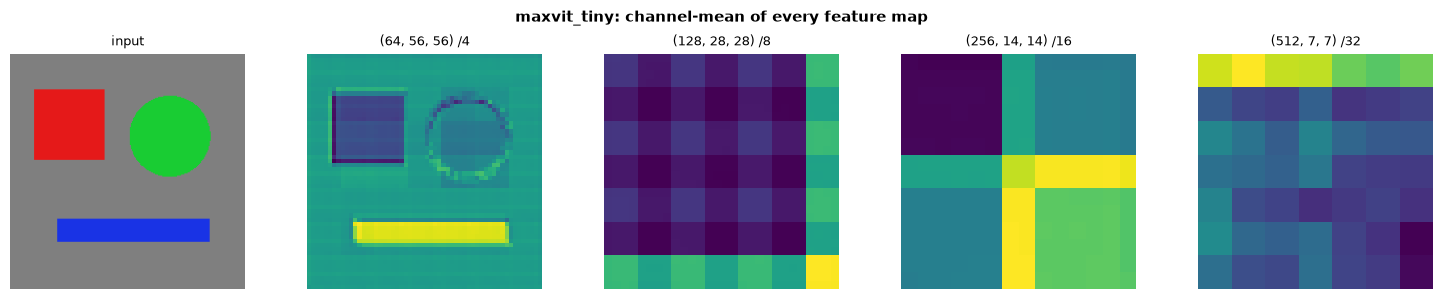

In [28]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [29]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [30]:
import sys
import torch

# ── Verify partition/unpartition round-trips ───────────────────────────────
print('=== Partition Round-trip Test ===')
B, H, W, C, P = 2, 8, 8, 32, 4
x = torch.randn(B, H, W, C)

blocks = block_partition(x, P)
x_rec  = block_reverse(blocks, P, H, W)
print(f'Block partition:   {tuple(x.shape)} → {tuple(blocks.shape)} → {tuple(x_rec.shape)}')
print(f'  Max abs error: {(x - x_rec).abs().max():.2e}  (should be ~0)')

grids  = grid_partition(x, P)
x_rec2 = grid_reverse(grids, P, H, W)
print(f'Grid  partition:   {tuple(x.shape)} → {tuple(grids.shape)} → {tuple(x_rec2.shape)}')
print(f'  Max abs error: {(x - x_rec2).abs().max():.2e}  (should be ~0)')

print()

# ── Build MaxViT-Tiny and trace shapes ─────────────────────────────────────
print('=== MaxViT-Tiny Shape Trace ===')
backbone = build_vision_backbone('maxvit_tiny', img_size=224)
backbone.eval()
print(f'Parameters: {backbone.num_parameters():,}')
print(f'Embed dim:  {backbone.embed_dim}')
print()

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    out = backbone(x)

print('BackboneOutput:')
print(f'  pooled_output : {tuple(out.pooled_output.shape)}')
print(f'  feature_maps  : {[tuple(fm.shape) for fm in out.feature_maps]}')

# Demonstrate dynamic relative bias: block N=64, grid N=49 for stage-0 (56×56, P=8)
stage0_block = list(backbone.stages[0].blocks.children())[0]
P_val = stage0_block.block_size
H_val = 56  # after stem
block_N = P_val ** 2
grid_N  = (H_val // P_val) ** 2
print(f'\nBlock attn: P={P_val}, window N={block_N}')
print(f'Grid  attn: H//P={H_val//P_val}, window N={grid_N}')
print(f'rel_bias table size: {stage0_block.block_attn.attn.rel_bias_table.shape}')
print(f'Block uses stored index, grid builds index dynamically (N mismatch).')

=== Partition Round-trip Test ===
Block partition:   (2, 8, 8, 32) → (8, 4, 4, 32) → (2, 8, 8, 32)
  Max abs error: 0.00e+00  (should be ~0)
Grid  partition:   (2, 8, 8, 32) → (32, 2, 2, 32) → (2, 8, 8, 32)
  Max abs error: 0.00e+00  (should be ~0)

=== MaxViT-Tiny Shape Trace ===


Parameters: 23,805,292
Embed dim:  512



BackboneOutput:
  pooled_output : (1, 512)
  feature_maps  : [(1, 64, 56, 56), (1, 128, 28, 28), (1, 256, 14, 14), (1, 512, 7, 7)]

Block attn: P=8, window N=64
Grid  attn: H//P=7, window N=49
rel_bias table size: torch.Size([225, 2])
Block uses stored index, grid builds index dynamically (N mismatch).


## Paper Citation & Related Work

### Primary Reference

> Z. Tu, H. Talebi, H. Zhang, F. Yang, P. Milanfar, A. Bovik, and Y. Li,
> "MaxViT: Multi-Axis Vision Transformer,"
> in *Proceedings of the European Conference on Computer Vision (ECCV)*, 2022, pp. 459–479.
> **arXiv:** https://arxiv.org/abs/2204.01697

### Related Work

| Model | Key Idea | Reference |
|-------|----------|----------|
| Swin Transformer | Hierarchical shifted-window attn | Liu et al., ICCV 2021 |
| ViL | Hierarchical global + local | Zhang et al., ICCV 2021 |
| CoAtNet | Conv stem + attention stages | Dai et al., NeurIPS 2021 |
| HiLo | Local-global attention split by freq. | Pan et al., NeurIPS 2022 |
| ViTDet | ViT backbone with windowed attn + FPN | Li et al., ECCV 2022 |

### Key Results from Paper

- **MaxViT-T:** 83.62% ImageNet top-1 at 31 M params — matches Swin-B (88 M)
- **MaxViT-L:** 86.40% at 212 M params (no extra data)
- **MaxViT-XL (JFT-pretrained):** 88.70% top-1 on ImageNet
- Scales from 224 to 512px with consistent improvement: +2.7% for MaxViT-XL
- Object detection COCO AP: 57.5 box AP with MaxViT-L backbone (ATSS detector)

### Complexity Comparison

| Method | Attention Cost |
|--------|---------------|
| ViT | $O(N^2)$ |
| Swin | $O(N \cdot P^2)$ — local only |
| MaxViT | $O(N \cdot P^2)$ — local **and** global |
| Performer / Linformer | $O(N)$ — approx, loses accuracy |
